# 基础模型对比与调参：双方各走10步后

比较多数类基线、逻辑回归、高斯朴素贝叶斯、单棵决策树、随机森林和直方图梯度提升。
目标为黑胜、和棋、白胜三类；输入为赛前6列或赛前＋开局46列。

**Run All仅读取保存的开发结果与图，不训练、不打开测试集。**
训练入口：`run_baseline_models20.py`、`run_decision_tree20.py`。
提交说明见[docs/SUBMISSION_ZH.md](docs/SUBMISSION_ZH.md)。神经网络不在本次提交范围。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"artifacts/plan_a20/feature_contract.json").exists()), None)
assert root is not None, "Open this notebook in the Chess checkout"
run = root/"modelling_baselines/run_20261025_20ply_01"
assert (run/"artifacts/development_complete.json").exists(), "Run the experiment first"
metrics = pd.read_csv(run/"tables/validation_metrics.csv")
frozen = json.loads((run/"artifacts/frozen_config.json").read_text(encoding="utf-8"))
protocol = json.loads((run/"artifacts/protocol.json").read_text(encoding="utf-8"))
print("Observation:", protocol["prediction_ply"], "plies; labels:", protocol["labels"])
print("Training: 11,936; validation: 2,549; test not loaded in this experiment")
print("Python:", protocol["python"], "sklearn:", protocol["packages"]["scikit-learn"])

Observation: 20 plies; labels: ['black', 'draw', 'white']
Training: 11,936; validation: 2,549; test not loaded in this experiment
Python: 3.12.15 sklearn: 1.8.0


## 实验设计

两套输入使用完全相同的对局：赛前6列，以及加入前20半回合局面信息后的46列。每个模型、每套特征独立在训练内三折时间CV选参，Macro-F1优先；冻结后才读取验证标签。

“初始”沿用仓库starter，不全部等同于sklearn默认参数。LR和GaussianNB折内标准化，树模型不标准化；全部折内拟合插补与常量列移除。

In [2]:
display(pd.read_csv(run/"tables/cv_folds.csv"))
print(protocol["selection"])
print("Search candidates per feature set:", {k:len(v) for k,v in protocol["candidate_grids"].items()})
display(pd.DataFrame(frozen["selected"]))

,fold,train_rows,cv_rows,train_last_start,cv_first_start
0,1,2982,2998,2016-05-06 18:40:00+00:00,2016-05-08 01:13:20+00:00
1,2,5966,2984,2017-02-08 18:53:20+00:00,2017-02-10 01:26:40+00:00
2,3,8933,2969,2017-06-05 20:00:25.406000+00:00,2017-06-07 00:00:03.484000+00:00


Per family AND feature set: highest mean training CV Macro-F1; tie: lower mean CV log loss, then lower candidate ID. Validation cannot change selection.
Search candidates per feature set: {'dummy': 0, 'logistic': 8, 'gaussian_nb': 8, 'random_forest': 12, 'gradient_boosting': 8}


,feature_set,family,candidate,parameters
0,pregame,logistic,4,"{'C': 1.0, 'class_weight': None}"
1,pregame,gaussian_nb,4,"{'var_smoothing': 0.001, 'priors': None}"
2,pregame,random_forest,7,"{'n_estimators': 200, 'max_depth': 16, 'min_sa..."
3,pregame,gradient_boosting,2,"{'max_iter': 150, 'learning_rate': 0.1, 'max_l..."
4,combined,logistic,2,"{'C': 0.1, 'class_weight': None}"
5,combined,gaussian_nb,6,"{'var_smoothing': 0.1, 'priors': None}"
6,combined,random_forest,3,"{'n_estimators': 200, 'max_depth': 8, 'min_sam..."
7,combined,gradient_boosting,0,"{'max_iter': 150, 'learning_rate': 0.1, 'max_l..."


## 初始模型与CV调参后的验证表现

主要同时看Macro-F1、Accuracy及和棋Precision/Recall。调参目标不是单独最大化Accuracy；没有上升的结果也保留。

,feature_set,family,stage,accuracy,macro_f1,balanced_accuracy,draw_precision,draw_recall,draw_f1,log_loss,macro_auc
0,pregame,dummy,initial,0.4861,0.2181,0.3333,0.0000,0.0000,0.0000,18.5238,0.5000
1,pregame,logistic,initial,0.5971,0.4067,0.4171,0.0000,0.0000,0.0000,0.7898,0.6490
2,pregame,logistic,tuned,0.5971,0.4067,0.4171,0.0000,0.0000,0.0000,0.7898,0.6490
3,pregame,gaussian_nb,initial,0.5920,0.4188,0.4213,0.0909,0.0250,0.0392,0.8403,0.6490
4,pregame,gaussian_nb,tuned,0.5920,0.4188,0.4213,0.0909,0.0250,0.0392,0.8402,0.6491
5,pregame,random_forest,initial,0.5806,0.3954,0.4055,0.0000,0.0000,0.0000,0.8131,0.6340
6,pregame,random_forest,tuned,0.5594,0.4248,0.4291,0.0688,0.1250,0.0888,0.9058,0.6325
7,pregame,gradient_boosting,initial,0.5944,0.4103,0.4177,0.5000,0.0083,0.0164,0.8100,0.6410
8,pregame,gradient_boosting,tuned,0.5983,0.4077,0.4180,0.0000,0.0000,0.0000,0.7877,0.6643
9,combined,dummy,initial,0.4861,0.2181,0.3333,0.0000,0.0000,0.0000,18.5238,0.5000


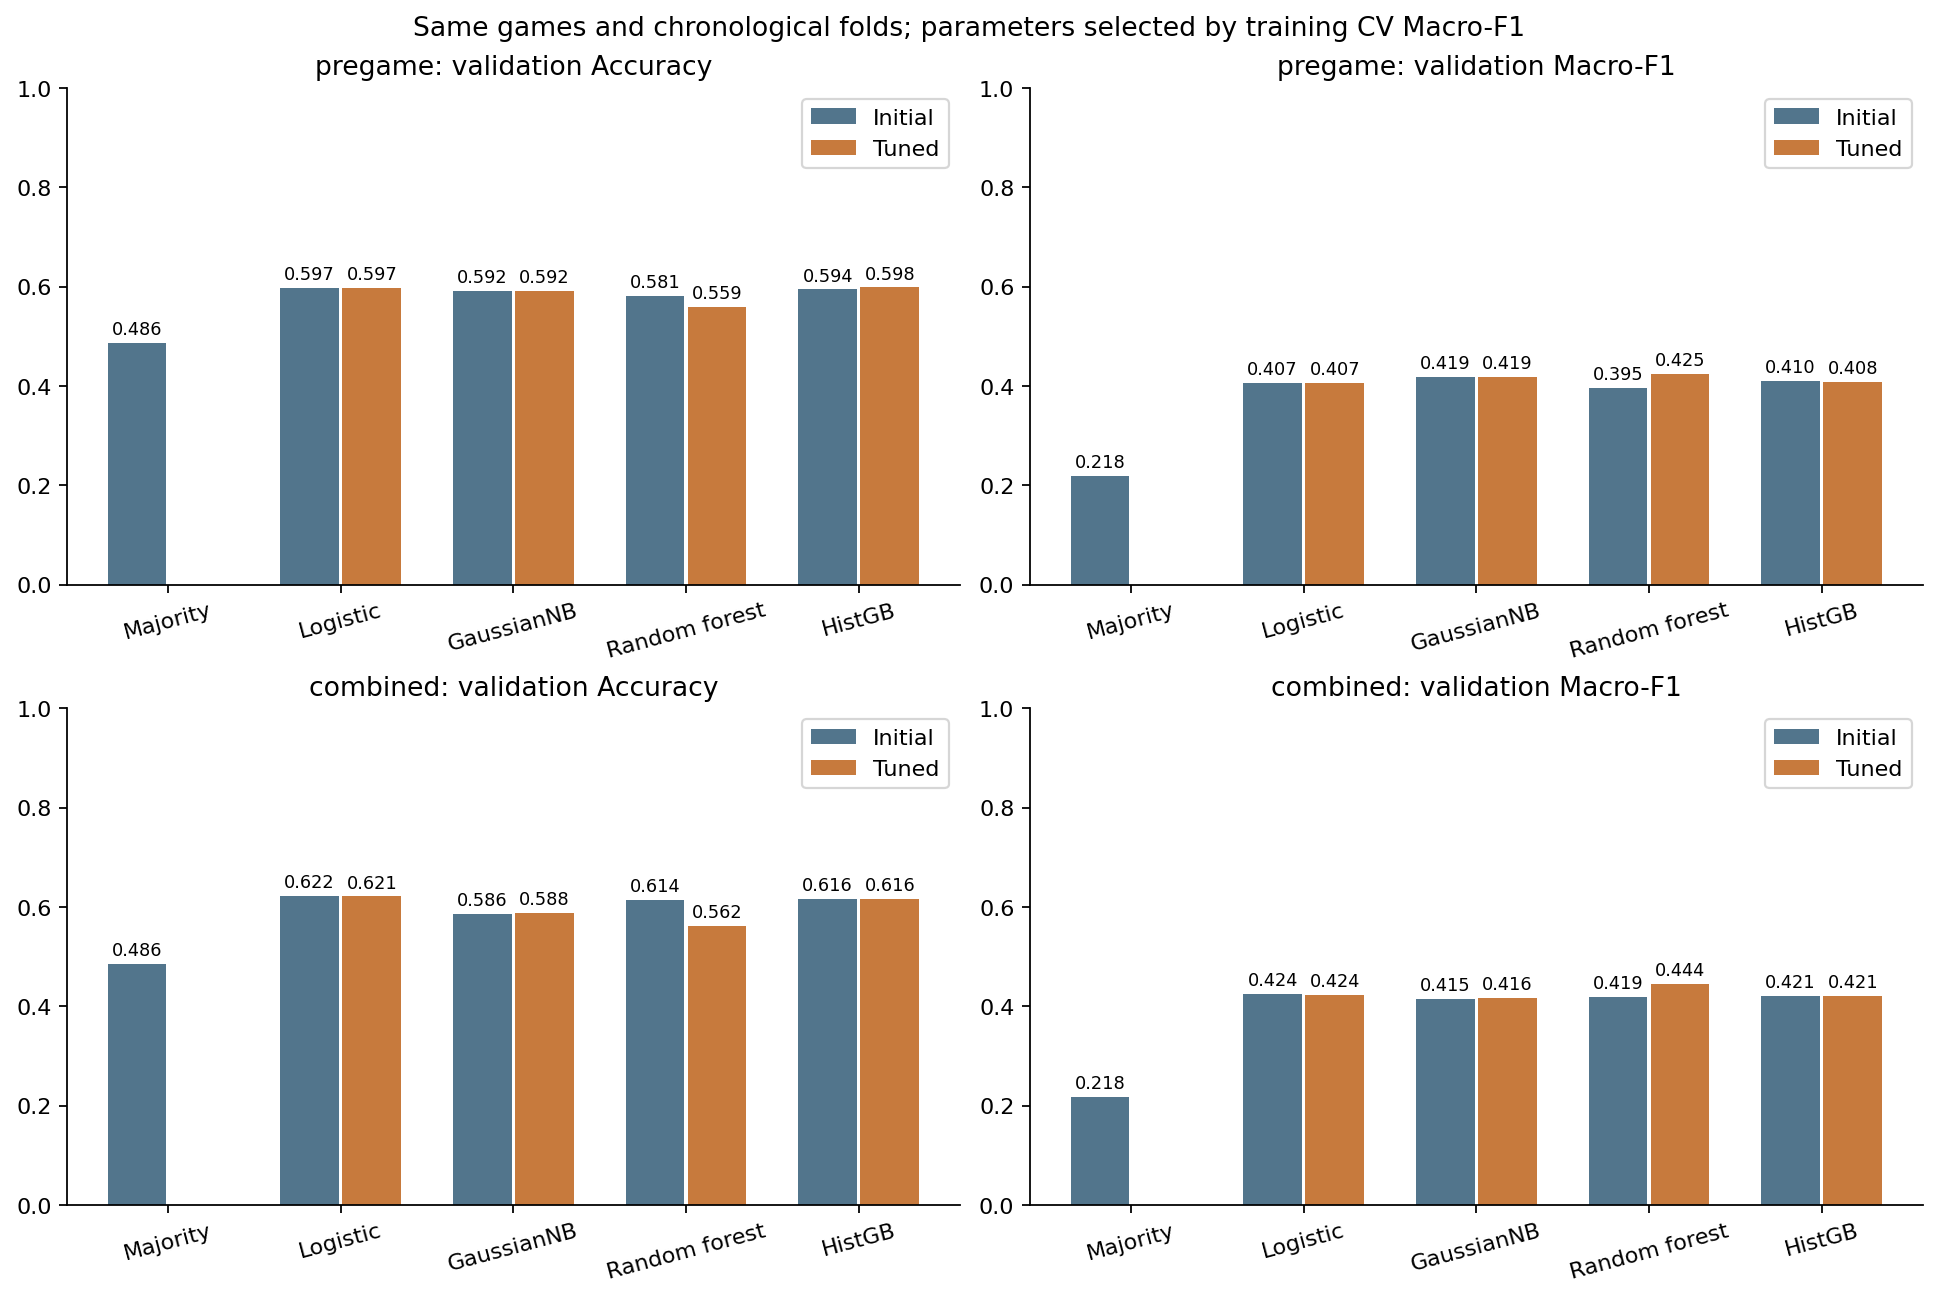

In [3]:
columns = ["feature_set", "family", "stage", "accuracy", "macro_f1", "balanced_accuracy", "draw_precision", "draw_recall", "draw_f1", "log_loss", "macro_auc"]
display(metrics[columns].round(4))
display(Image(filename=str(run/"figures/01_validation_comparison.png")))

## 调参变化与训练／验证差距

调参变化是同一模型、同一特征队列的比较；Log Loss下降为改善。训练分数高但验证低可能提示过拟合，也需考虑时间分布变化。

,feature_set,family,accuracy_initial,accuracy_tuned,macro_f1_initial,macro_f1_tuned,draw_recall_initial,draw_recall_tuned,log_loss_initial,log_loss_tuned,accuracy_delta,macro_f1_delta,draw_recall_delta,log_loss_delta
0,combined,gaussian_nb,0.5861,0.5881,0.4147,0.4161,0.0250,0.0250,1.4294,1.2998,0.0020,0.0014,0.0000,-0.1296
1,combined,gradient_boosting,0.6163,0.6163,0.4207,0.4207,0.0000,0.0000,0.7920,0.7828,0.0000,-0.0000,0.0000,-0.0092
2,combined,logistic,0.6218,0.6210,0.4241,0.4236,0.0000,0.0000,0.7795,0.7795,-0.0008,-0.0005,0.0000,0.0000
3,combined,random_forest,0.6140,0.5618,0.4189,0.4443,0.0000,0.2333,0.7826,0.9837,-0.0522,0.0254,0.2333,0.2012
4,pregame,gaussian_nb,0.5920,0.5920,0.4188,0.4188,0.0250,0.0250,0.8403,0.8402,0.0000,0.0000,0.0000,-0.0001
5,pregame,gradient_boosting,0.5944,0.5983,0.4103,0.4077,0.0083,0.0000,0.8100,0.7877,0.0039,-0.0026,-0.0083,-0.0223
6,pregame,logistic,0.5971,0.5971,0.4067,0.4067,0.0000,0.0000,0.7898,0.7898,0.0000,0.0000,0.0000,0.0000
7,pregame,random_forest,0.5806,0.5594,0.3954,0.4248,0.0000,0.1250,0.8131,0.9058,-0.0212,0.0294,0.1250,0.0927


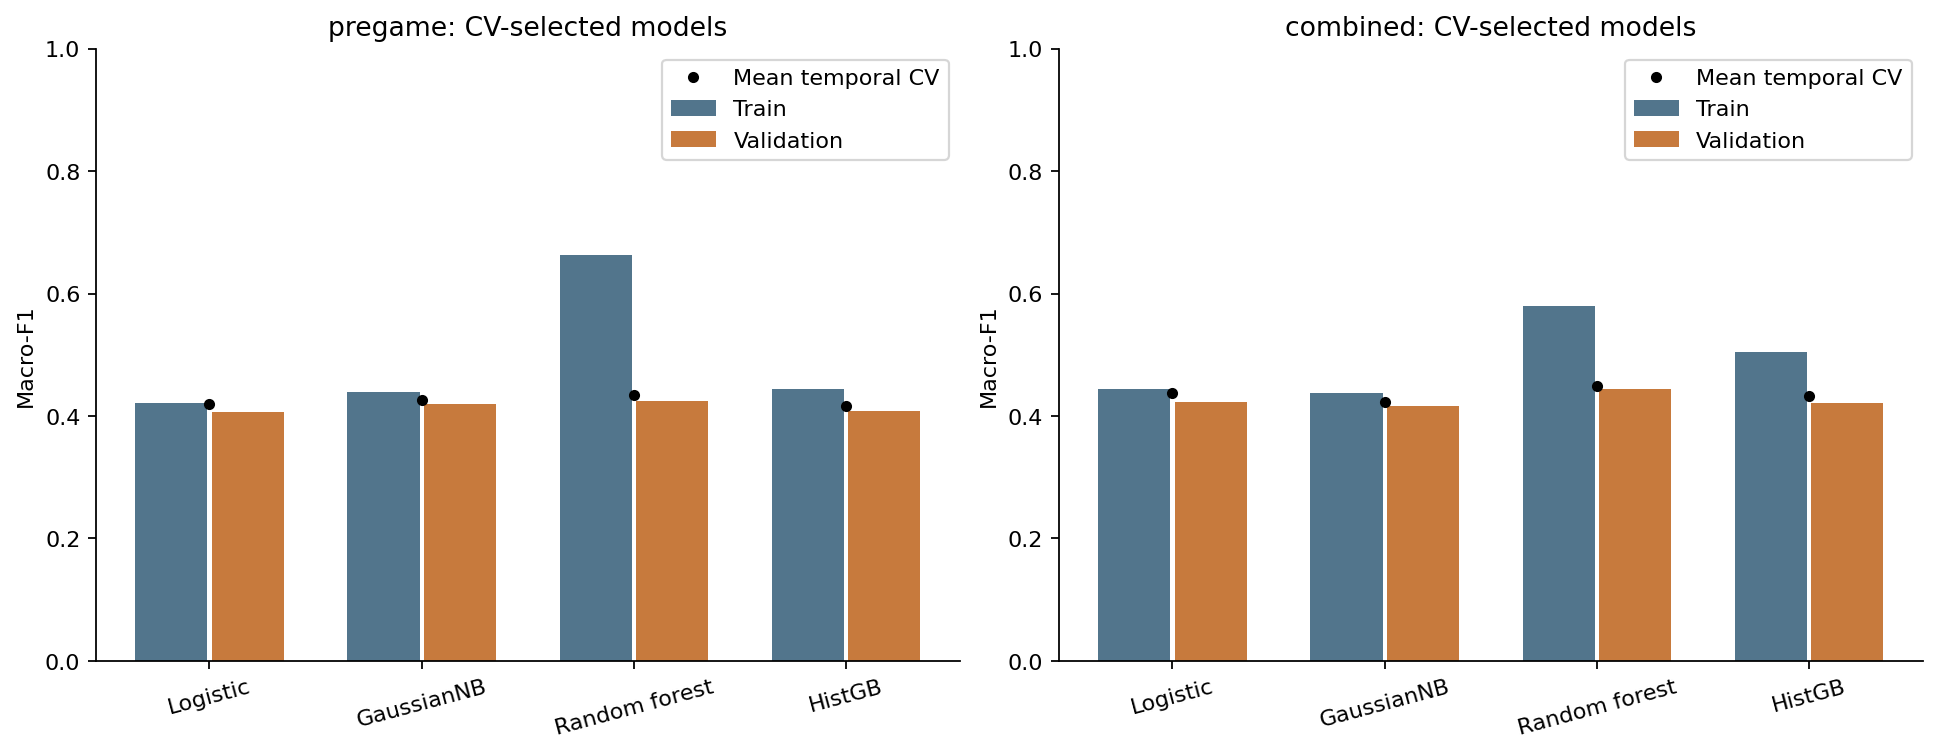

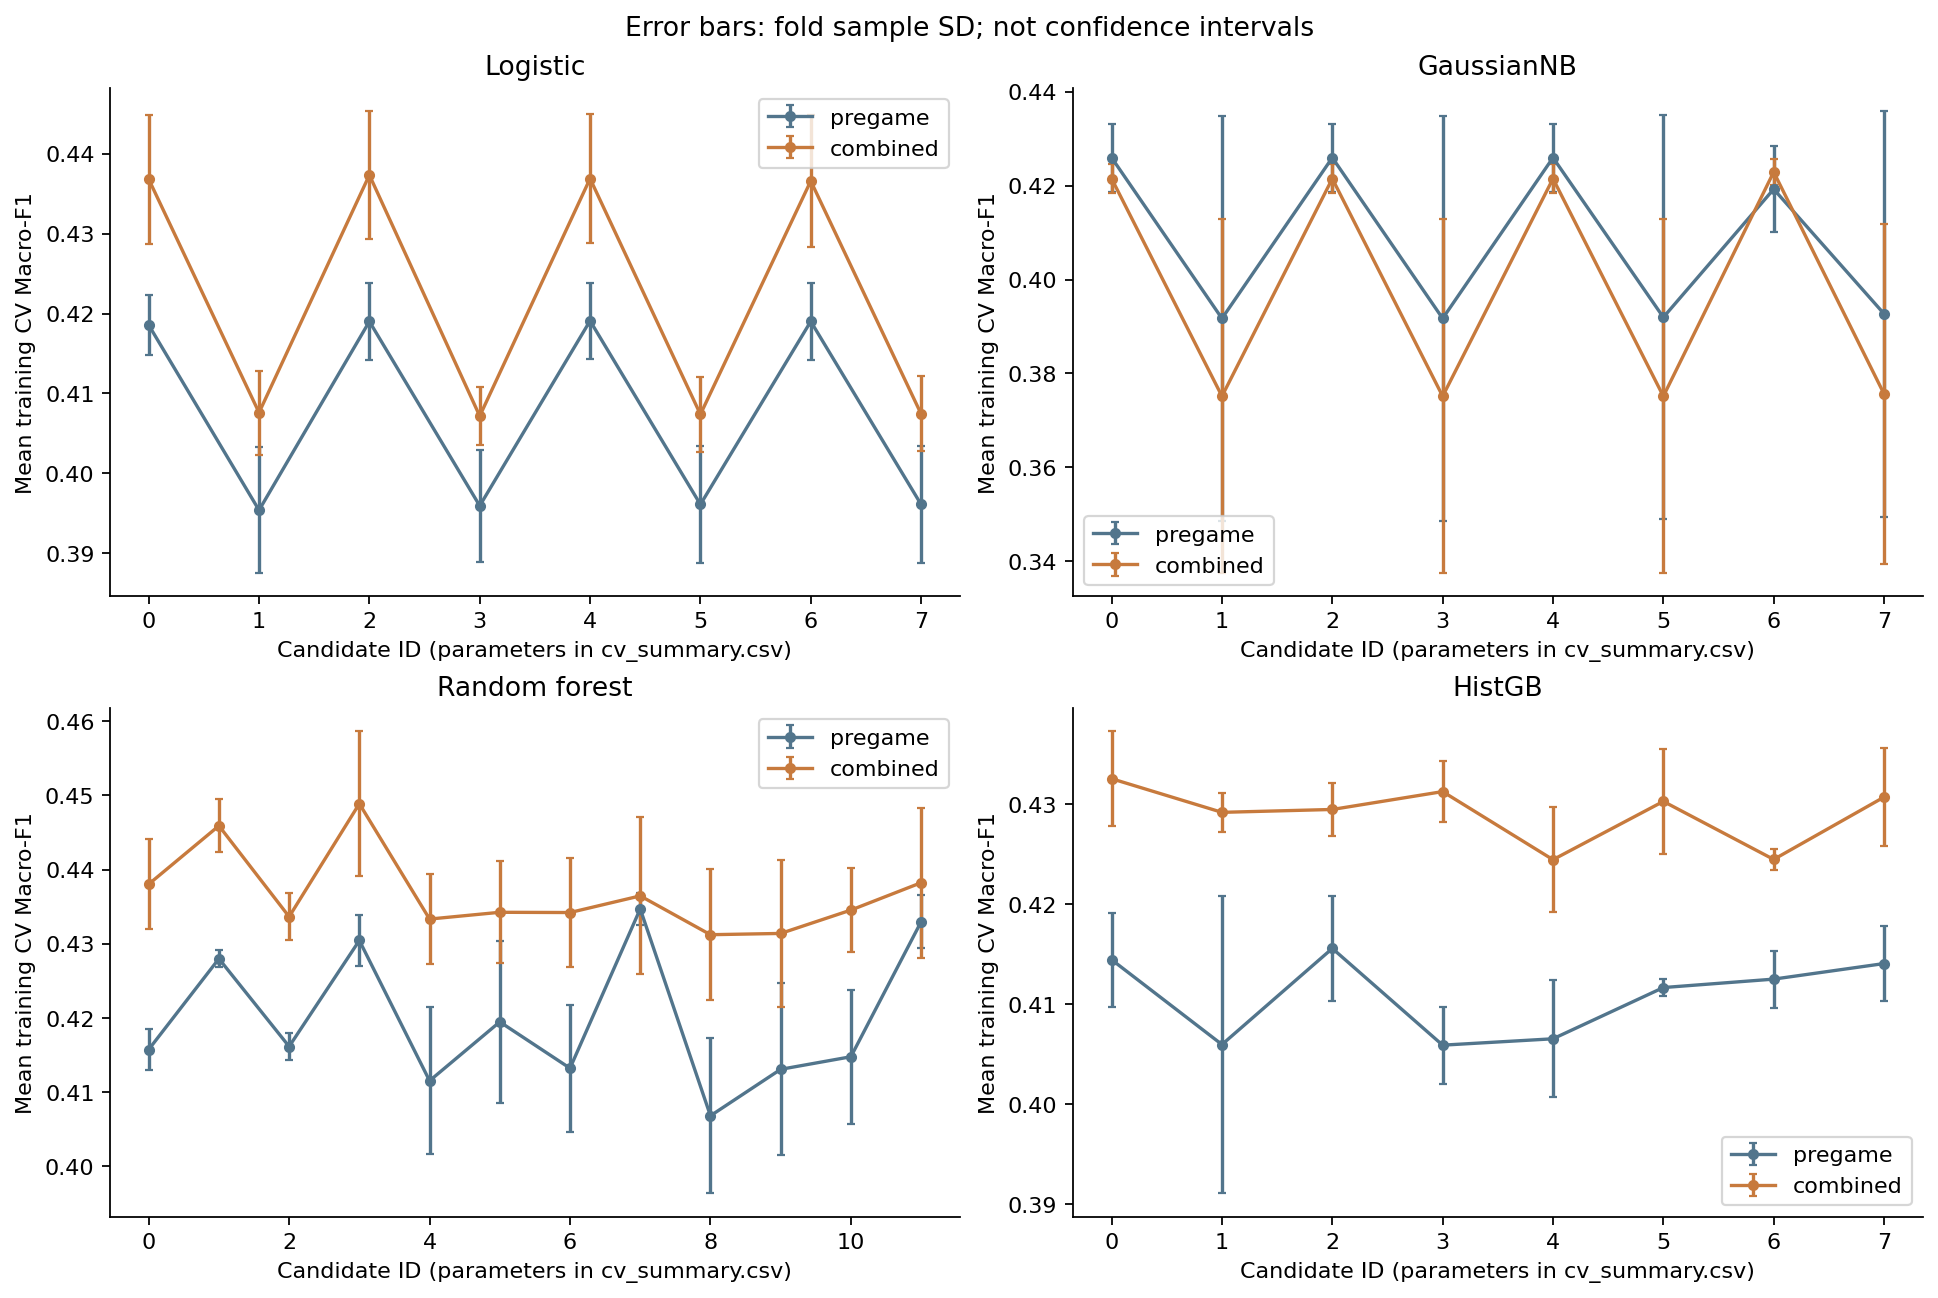

In [4]:
display(pd.read_csv(run/"tables/tuning_changes.csv").round(4))
display(Image(filename=str(run/"figures/03_training_validation_gap.png")))
display(Image(filename=str(run/"figures/04_search_cv_scores.png")))

## 46列模型的三分类错误与概率排序

混淆矩阵每行是真实类别；和棋基数小，Recall必须结合Precision。ROC AUC评价概率排序，不能替代分类准确率或概率校准。

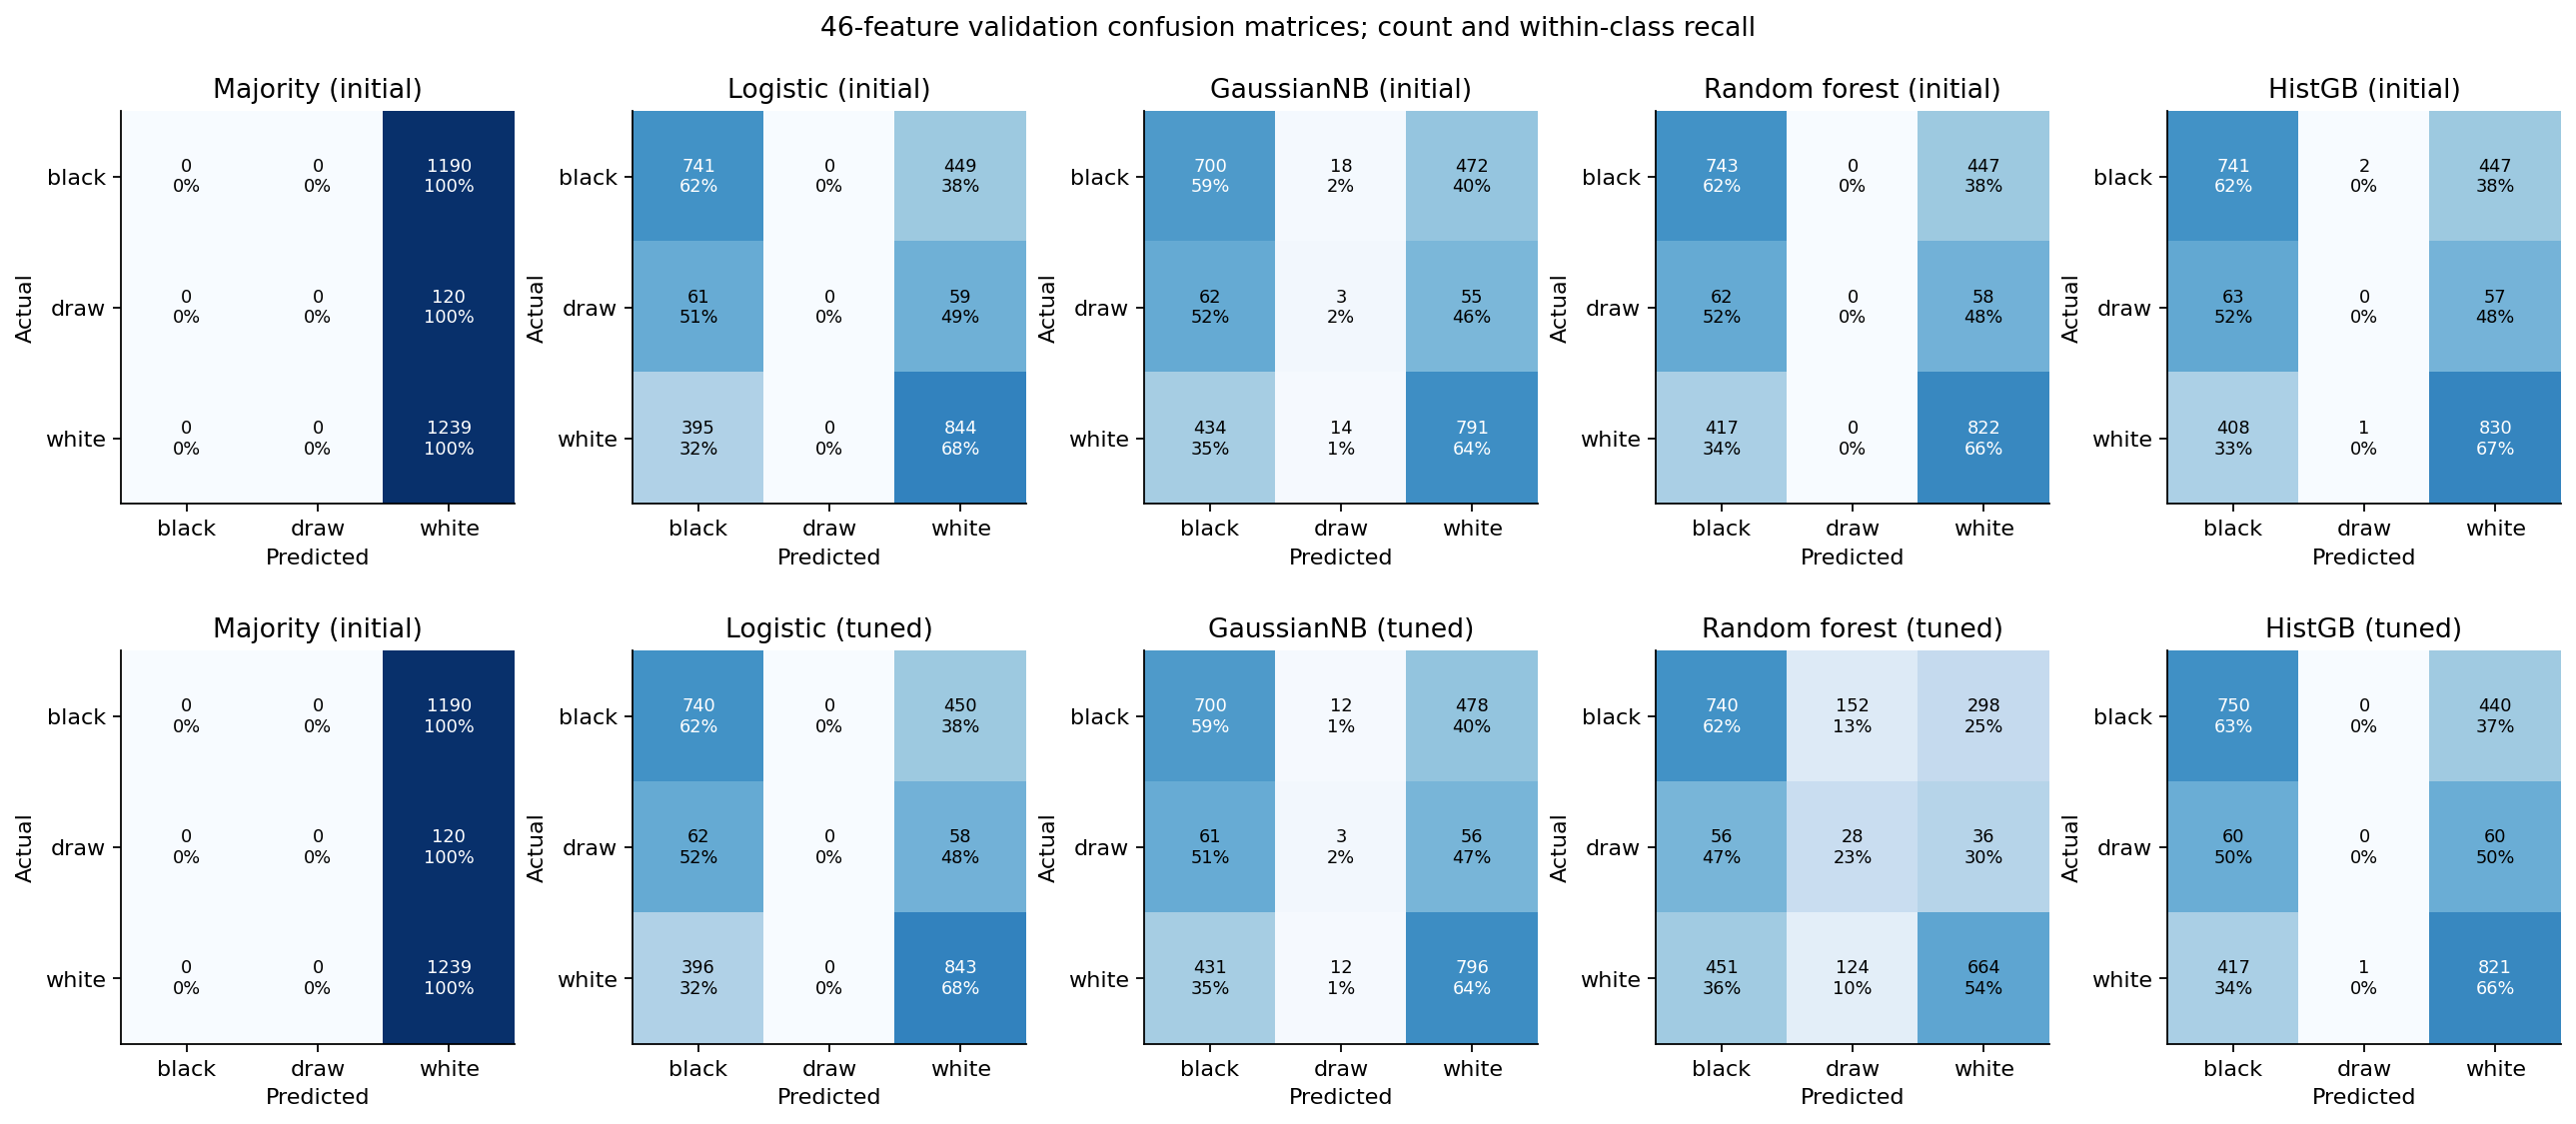

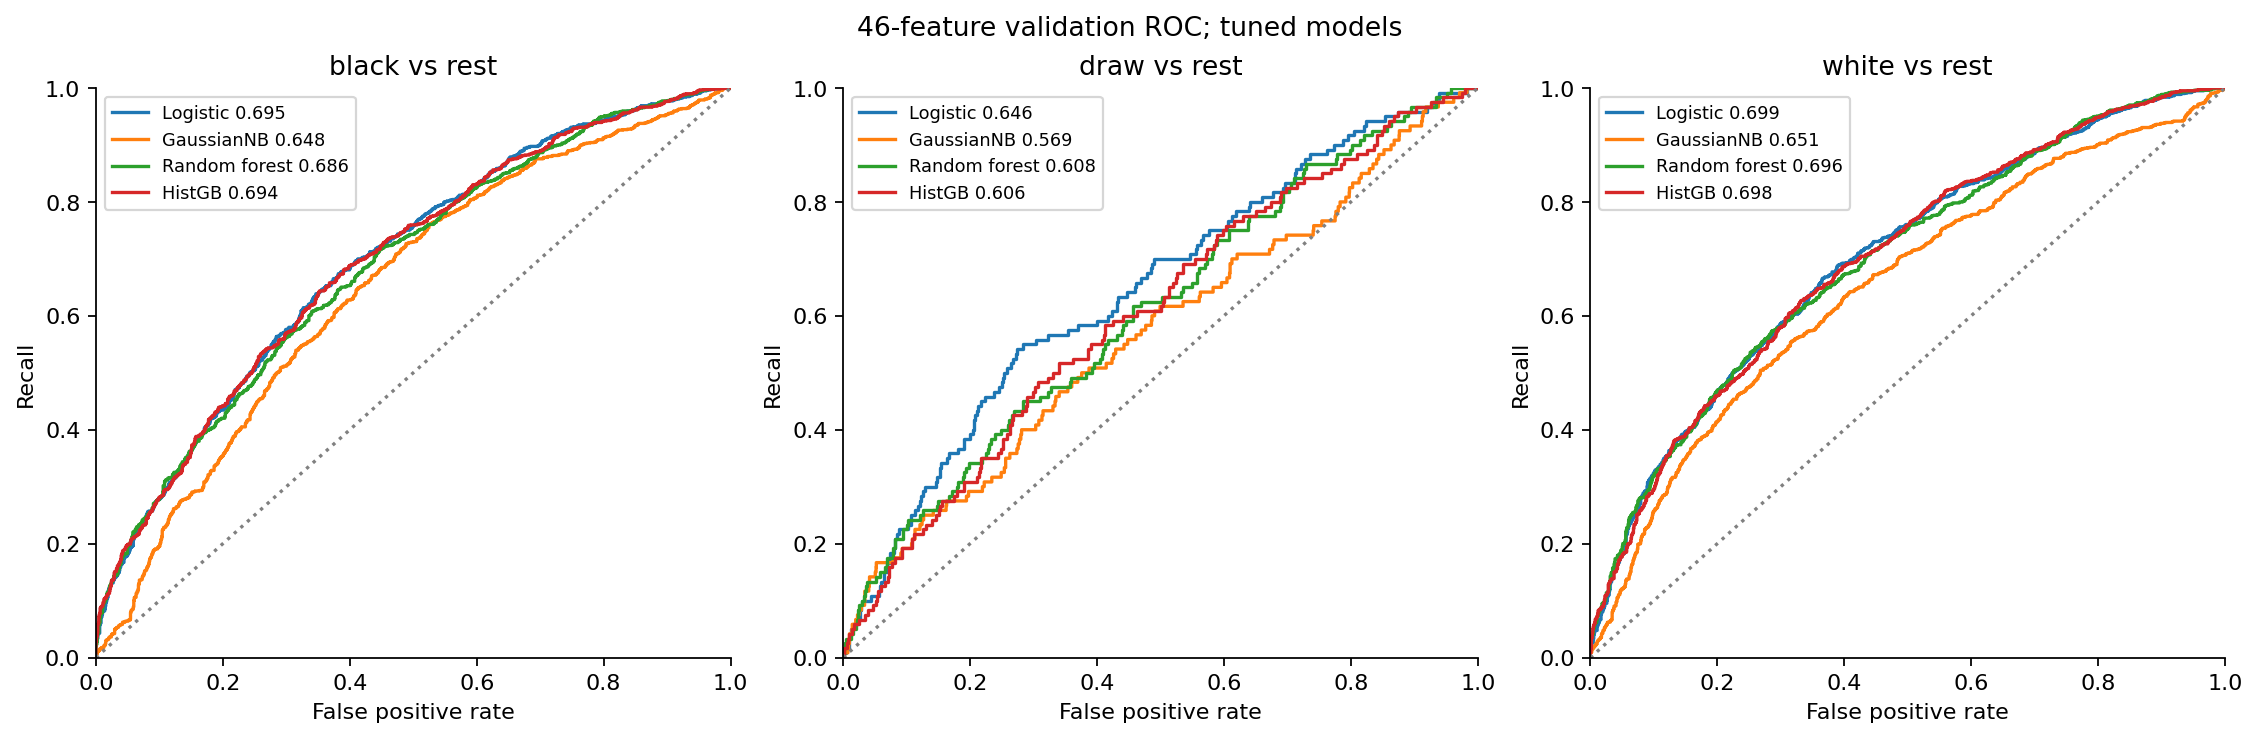

,slug,class,precision,recall,f1-score,support
0,pregame_dummy_initial,black,0.0000,0.0000,0.0000,1190.0
1,pregame_dummy_initial,draw,0.0000,0.0000,0.0000,120.0
2,pregame_dummy_initial,white,0.4861,1.0000,0.6542,1239.0
3,pregame_logistic_initial,black,0.5998,0.5756,0.5875,1190.0
4,pregame_logistic_initial,draw,0.0000,0.0000,0.0000,120.0
5,pregame_logistic_initial,white,0.5949,0.6755,0.6327,1239.0
6,pregame_logistic_tuned,black,0.5998,0.5756,0.5875,1190.0
7,pregame_logistic_tuned,draw,0.0000,0.0000,0.0000,120.0
8,pregame_logistic_tuned,white,0.5949,0.6755,0.6327,1239.0
9,pregame_gaussian_nb_initial,black,0.5964,0.5924,0.5944,1190.0


In [5]:
display(Image(filename=str(run/"figures/02_combined_confusion.png")))
display(Image(filename=str(run/"figures/05_combined_roc.png")))
display(pd.read_csv(run/"tables/validation_per_class.csv").round(4))

## 检查与限制

本轮没有新的测试结果。原测试时期已被早期实验查看，验证集也经历多轮探索，因此这里是开发比较。原RF为两个信息集选共享参数，本轮独立选参，不能直接把结果差归因于算法。

重现逐局验证概率：`python verify_baseline_models20.py --reload-models`。新增实验使用新输出目录，避免覆盖。

In [6]:
verification = json.loads((run/"artifacts/result_verification.json").read_text(encoding="utf-8"))
print("Verification:", verification["status"], verification["check_count"], "checks")
print("Test loaded:", verification["test_loaded"])
print("Full report:", (run/"RESULTS_ZH.md").relative_to(root))

Verification: passed 240 checks
Test loaded: False
Full report: modelling_baselines\run_20261025_20ply_01\RESULTS_ZH.md


## 单棵决策树补充实验

相同时间分区和20半回合输入，默认决策树不限制深度；20组正则化设置在训练内时间CV选参。比较树深、训练／验证差距与分类别结果。

本补充是统一数值特征决策树，不是参考项目按完整开局分组并排除罕见前缀的流程。

,feature_set,stage,actual_depth,leaf_count,train_accuracy,accuracy,macro_f1,draw_precision,draw_recall,parameters
0,pregame,initial,42,4301,0.9911,0.5065,0.3668,0.0427,0.0417,{}
1,pregame,tuned,3,8,0.6215,0.5912,0.3954,0.0000,0.0000,"{""max_depth"": 3, ""min_samples_leaf"": 5, ""class..."
2,combined,initial,38,2965,0.9999,0.5265,0.3858,0.0538,0.0583,{}
3,combined,tuned,3,8,0.6356,0.6022,0.4088,0.0000,0.0000,"{""max_depth"": 3, ""min_samples_leaf"": 5, ""class..."


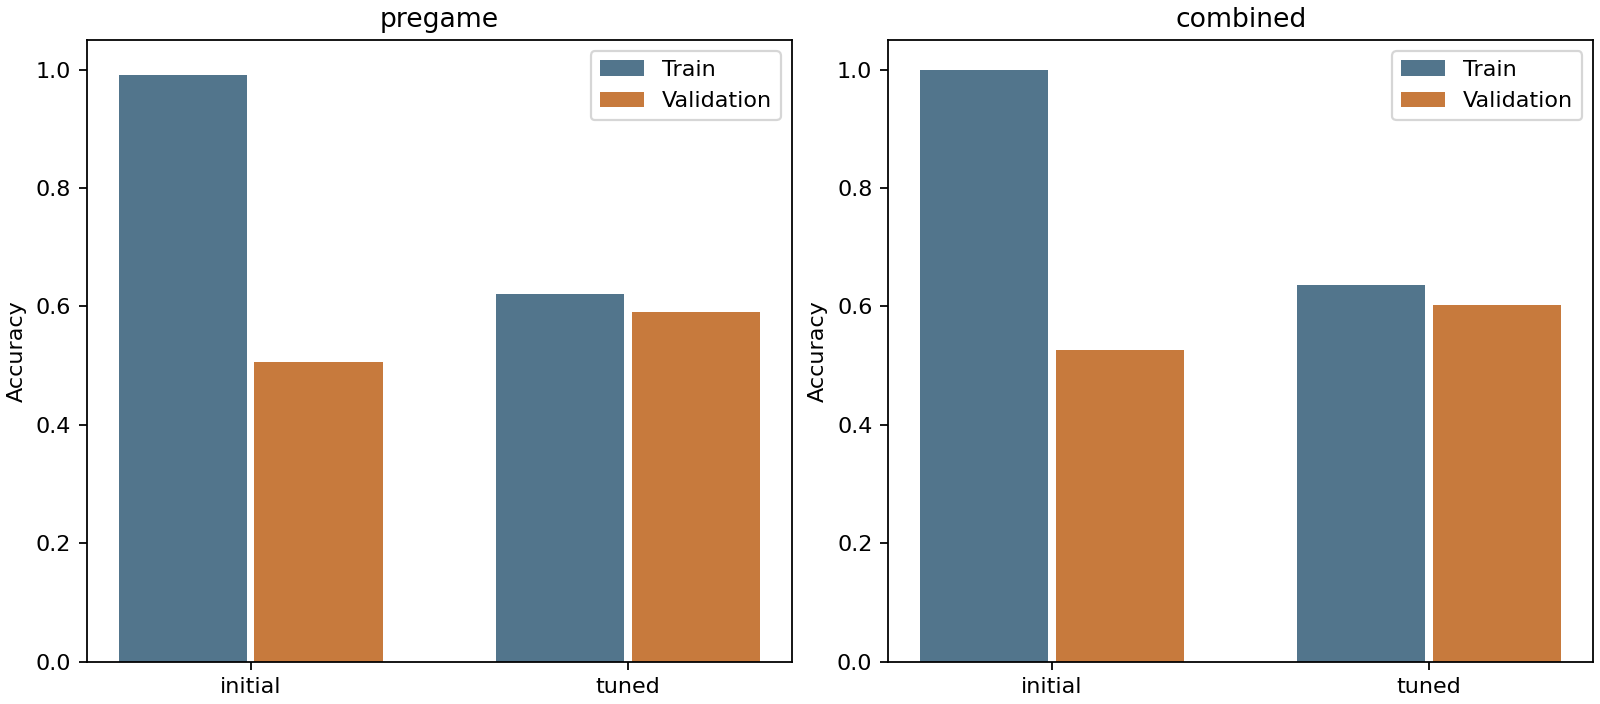

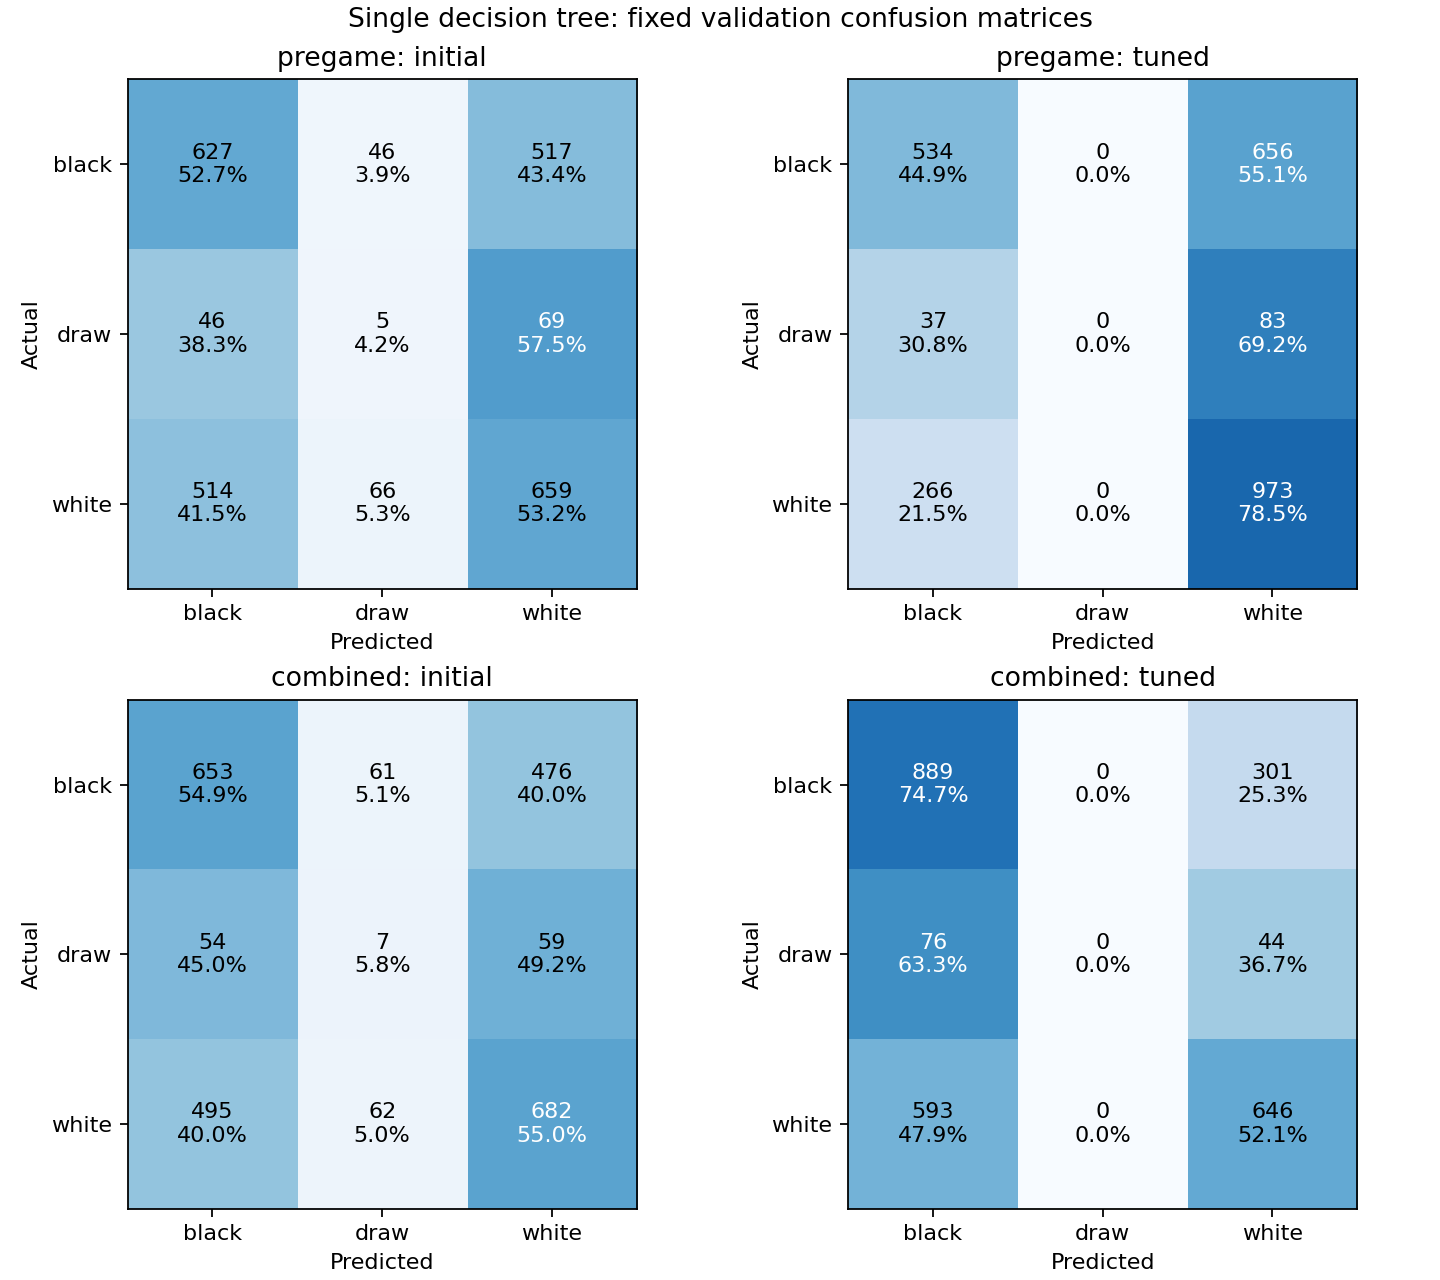

In [7]:
tree_run = root/"modelling_baselines/run_20261025_tree_01"
tree_metrics = pd.read_csv(tree_run/"tables/validation_metrics.csv")
display(tree_metrics[["feature_set", "stage", "actual_depth", "leaf_count", "train_accuracy", "accuracy", "macro_f1", "draw_precision", "draw_recall", "parameters"]].round(4))
display(Image(filename=str(tree_run/"figures/training_validation_gap.png")))
display(Image(filename=str(tree_run/"figures/confusion_matrices.png")))

In [8]:
tree_rows = tree_metrics.assign(family="decision_tree")
comparison = pd.concat([metrics, tree_rows], ignore_index=True)
display(comparison.loc[comparison.feature_set.eq("combined"), ["family", "stage", "accuracy", "macro_f1", "draw_precision", "draw_recall"]].round(4))
print("Single-tree report:", (tree_run/"RESULTS_ZH.md").relative_to(root))

,family,stage,accuracy,macro_f1,draw_precision,draw_recall
9,dummy,initial,0.4861,0.2181,0.0000,0.0000
10,logistic,initial,0.6218,0.4241,0.0000,0.0000
11,logistic,tuned,0.6210,0.4236,0.0000,0.0000
12,gaussian_nb,initial,0.5861,0.4147,0.0857,0.0250
13,gaussian_nb,tuned,0.5881,0.4161,0.1111,0.0250
14,random_forest,initial,0.6140,0.4189,0.0000,0.0000
15,random_forest,tuned,0.5618,0.4443,0.0921,0.2333
16,gradient_boosting,initial,0.6163,0.4207,0.0000,0.0000
17,gradient_boosting,tuned,0.6163,0.4207,0.0000,0.0000
20,decision_tree,initial,0.5265,0.3858,0.0538,0.0583


Single-tree report: modelling_baselines\run_20261025_tree_01\RESULTS_ZH.md


## 全部模型的统一比较图

同队列、同观察时点的初始与CV调参后结果；多数类不调参。完整数值和解释见[统一比较说明](modelling_baselines/comparison_20ply/COMPARISON_ZH.md)。

![全部模型比较](modelling_baselines/comparison_20ply/all_models_comparison.png)

In [9]:
selected = pd.read_csv(root / "modelling_baselines/comparison_20ply/cv_selected_metrics.csv")
assert set(selected.family) == {"dummy", "logistic", "gaussian_nb", "decision_tree", "random_forest", "gradient_boosting"}
display(selected[["feature_set", "family", "accuracy", "macro_f1", "draw_precision", "draw_recall", "log_loss"]].round(4))

,feature_set,family,accuracy,macro_f1,draw_precision,draw_recall,log_loss
0,pregame,dummy,0.4861,0.2181,0.0000,0.0000,18.5238
1,pregame,logistic,0.5971,0.4067,0.0000,0.0000,0.7898
2,pregame,gaussian_nb,0.5920,0.4188,0.0909,0.0250,0.8402
3,pregame,random_forest,0.5594,0.4248,0.0688,0.1250,0.9058
4,pregame,gradient_boosting,0.5983,0.4077,0.0000,0.0000,0.7877
5,combined,dummy,0.4861,0.2181,0.0000,0.0000,18.5238
6,combined,logistic,0.6210,0.4236,0.0000,0.0000,0.7795
7,combined,gaussian_nb,0.5881,0.4161,0.1111,0.0250,1.2998
8,combined,random_forest,0.5618,0.4443,0.0921,0.2333,0.9837
9,combined,gradient_boosting,0.6163,0.4207,0.0000,0.0000,0.7828


## 随机森林来源与报告范围

原仓库提交`0bf217e`已包含`src/rf_experiment20.py`、`run_rf_modelling20.py`及`modelling_rf/`全部RF实验。
原RF在两套特征间选共享参数，结合训练CV和验证选择；最终训练＋验证重训后报告历史测试成绩。
新增比较对每套特征独立按训练时间CV选参，仅在固定验证集评价。因此两套RF结果不应混作一次实验。

本表是开发验证结果；历史测试期已被先前探索查看，没有新的盲测。调参目标为Macro-F1，未改善的结果也完整保留。
